# Viajes en taxi en Chicago: competencia, destinos y efecto del clima

*Proyecto de Bootcamp – TripleTen (Sprint 8). Zuber es una empresa simulada; los datos son de taxis de Chicago de noviembre de 2017, preparados por TripleTen.*

**Contexto (caso simulado).** Zuber, una nueva empresa de viajes compartidos, se lanza en Chicago. El objetivo es entender las preferencias de los pasajeros y el impacto de factores externos (el clima) en los viajes.

**Etapas previas (ya realizadas):**
1. **Análisis sintáctico (parsing):** con `requests` y `BeautifulSoup` recuperé la tabla `weather_records` del clima en Chicago de noviembre de 2017 (ejercicio realizado en la plataforma).
2. **SQL:** consulté la base de datos (tablas `trips`, `cabs`, `neighborhoods`, `weather_records`) para obtener los viajes por empresa, los barrios de destino y los viajes del Loop a O'Hare en sábado junto con el clima (uniendo `trips.start_ts` con `weather_records.ts`). Las consultas están en `sql/zuber_queries.sql`.

**En este notebook:**
- Paso 4: análisis exploratorio de `project_sql_result_01.csv` y `project_sql_result_04.csv`.
- Paso 5: prueba de hipótesis con `project_sql_result_07.csv`.

## Resumen ejecutivo

- **Competencia:** el mercado está concentrado. Flash Cab hizo ≈19.600 viajes el 15 y 16 de noviembre, casi el doble que Taxi Affiliation Services (≈11.400). Las 10 primeras empresas (de 64) concentran el **72,3 %** de los viajes.
- **Destinos:** Loop (≈10.700 viajes promedio), River North (≈9.500), Streeterville (≈6.700) y West Loop (≈5.200). Los 10 barrios principales (de 94) concentran el **76,7 %** de las finalizaciones; O'Hare es el único destino fuera del centro en el top 5.
- **Calidad de datos:** en los viajes Loop → O'Hare eliminé 197 duplicados y 6 viajes de 0 segundos (1.068 → 865 viajes).
- **Clima:** los sábados con lluvia o tormenta, el viaje Loop → O'Hare dura en promedio **≈40,2 min frente a ≈34,2 min** con buen tiempo (≈6 min, ≈18 % más). Levene p ≈ 0,82 (varianzas iguales); prueba t p ≈ 1,54×10⁻⁷ → se rechaza H₀.
- **Limitaciones:** solo 148 viajes con lluvia, 4 sábados de un mes, y la hora del día puede ser un factor de confusión.
- **Recomendación:** concentrar conductores en el centro y en la ruta al aeropuerto; en días de lluvia, ajustar los tiempos estimados de llegada, las tarifas y la oferta de conductores.

## 1. Importar librerías y cargar los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

companies = pd.read_csv('data/project_sql_result_01.csv')   # viajes por empresa (15-16 nov 2017)
neighborhoods = pd.read_csv('data/project_sql_result_04.csv')  # promedio de viajes por barrio de destino (nov 2017)
trips = pd.read_csv('data/project_sql_result_07.csv')        # viajes Loop -> O'Hare en sábado con clima

## 2. Estudiar los datos

### 2.1 Empresas de taxis (`project_sql_result_01.csv`)

In [2]:
companies.info()
companies.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299
5,Chicago Carriage Cab Corp,9181
6,City Service,8448
7,Sun Taxi,7701
8,Star North Management LLC,7455
9,Blue Ribbon Taxi Association Inc.,5953


In [3]:
print('Valores ausentes:\n', companies.isna().sum())
print('Filas duplicadas:', companies.duplicated().sum())
print('Nombres de empresa duplicados:', companies['company_name'].duplicated().sum())
companies['trips_amount'].describe()

Valores ausentes:
 company_name    0
trips_amount    0
dtype: int64
Filas duplicadas: 0
Nombres de empresa duplicados: 0


count       64.000000
mean      2145.484375
std       3812.310186
min          2.000000
25%         20.750000
50%        178.500000
75%       2106.500000
max      19558.000000
Name: trips_amount, dtype: float64

**Comentario:** la tabla tiene 64 empresas y 2 columnas. `company_name` es texto (`object`) y `trips_amount` es entero (`int64`), que es el tipo correcto para un conteo. No hay valores ausentes ni duplicados. La distribución está muy sesgada: la media (≈2 145 viajes) es mucho mayor que la mediana (≈178), lo que indica que unas pocas empresas concentran la mayoría de los viajes.

### 2.2 Barrios de destino (`project_sql_result_04.csv`)

In [4]:
neighborhoods.info()
neighborhoods.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


In [5]:
print('Valores ausentes:\n', neighborhoods.isna().sum())
print('Filas duplicadas:', neighborhoods.duplicated().sum())
print('Barrios duplicados:', neighborhoods['dropoff_location_name'].duplicated().sum())
neighborhoods['average_trips'].describe()

Valores ausentes:
 dropoff_location_name    0
average_trips            0
dtype: int64
Filas duplicadas: 0
Barrios duplicados: 0


count       94.000000
mean       599.953728
std       1714.591098
min          1.800000
25%         14.266667
50%         52.016667
75%        298.858333
max      10727.466667
Name: average_trips, dtype: float64

**Comentario:** 94 barrios y 2 columnas. `dropoff_location_name` es texto y `average_trips` es `float64`, correcto porque es un **promedio** (puede tener decimales). No hay ausentes ni duplicados, así que no hace falta cambiar tipos de datos.

### 2.3 Viajes del Loop a O'Hare (`project_sql_result_07.csv`)

In [6]:
trips.info()
trips.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0
5,2017-11-11 04:00:00,Good,1320.0
6,2017-11-04 16:00:00,Bad,2969.0
7,2017-11-18 11:00:00,Good,2280.0
8,2017-11-11 14:00:00,Good,2460.0
9,2017-11-11 12:00:00,Good,2040.0


In [7]:
# start_ts se lee como texto: lo convertimos a fecha y hora
trips['start_ts'] = pd.to_datetime(trips['start_ts'])

print('Valores ausentes:\n', trips.isna().sum())
print('Filas duplicadas:', trips.duplicated().sum())
print('Viajes con duración 0 s:', (trips['duration_seconds'] == 0).sum())
print('Rango de fechas:', trips['start_ts'].min(), '-', trips['start_ts'].max())
print('Días de la semana:', trips['start_ts'].dt.day_name().unique())
trips['weather_conditions'].value_counts()

Valores ausentes:
 start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64
Filas duplicadas: 197
Viajes con duración 0 s: 6
Rango de fechas: 2017-11-04 00:00:00 - 2017-11-25 23:00:00
Días de la semana: ['Saturday']


Good    888
Bad     180
Name: weather_conditions, dtype: int64

**Comentario:**
- `start_ts` venía como texto; lo convertí a `datetime`. `duration_seconds` es `float64` (numérico, correcto) y `weather_conditions` es categórica (`Good`/`Bad`).
- Todos los viajes son en sábado (4, 11, 18 y 25 de noviembre de 2017), como se pidió en la consulta SQL.
- Hay **197 filas duplicadas**: registros idénticos en `start_ts`, `weather_conditions` y `duration_seconds`. Como no tenemos un `trip_id` que permita distinguirlos, no hay forma de saber si son viajes distintos, e incluirlos inflaría artificialmente los grupos y distorsionaría las medias. **Los elimino.**
- Hay **6 viajes con duración 0 s**: un viaje de 0 segundos no es un viaje real, sino un error de registro. **También los elimino** (ver la celda siguiente).

### 2.4 Limpieza de `trips`

Elimino los duplicados y los viajes con duración 0 antes de separar los grupos para la prueba de hipótesis.

In [8]:
rows_before = len(trips)

# 1) Eliminar filas duplicadas (idénticas en los 3 campos)
trips = trips.drop_duplicates().reset_index(drop=True)
# 2) Eliminar viajes con duración 0 s (errores de registro)
trips = trips[trips['duration_seconds'] > 0].reset_index(drop=True)

print('Filas antes de la limpieza:', rows_before)
print('Filas después de la limpieza:', len(trips))
print('Duplicados restantes:', trips.duplicated().sum())
print('Viajes con duración 0 s restantes:', (trips['duration_seconds'] == 0).sum())
trips['weather_conditions'].value_counts()

Filas antes de la limpieza: 1068
Filas después de la limpieza: 865
Duplicados restantes: 0
Viajes con duración 0 s restantes: 0


Good    717
Bad     148
Name: weather_conditions, dtype: int64

## 3. Top 10 de barrios por número de finalizaciones

In [9]:
top10_neighborhoods = (neighborhoods
                       .sort_values('average_trips', ascending=False)
                       .head(10)
                       .reset_index(drop=True))
top10_neighborhoods

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


In [10]:
share_top10 = top10_neighborhoods['average_trips'].sum() / neighborhoods['average_trips'].sum() * 100
print(f'Los 10 barrios principales concentran el {share_top10:.1f}% de las finalizaciones promedio')

Los 10 barrios principales concentran el 76.7% de las finalizaciones promedio


## 4. Gráficos

### 4.1 Empresas de taxis y número de viajes (15-16 de noviembre de 2017)

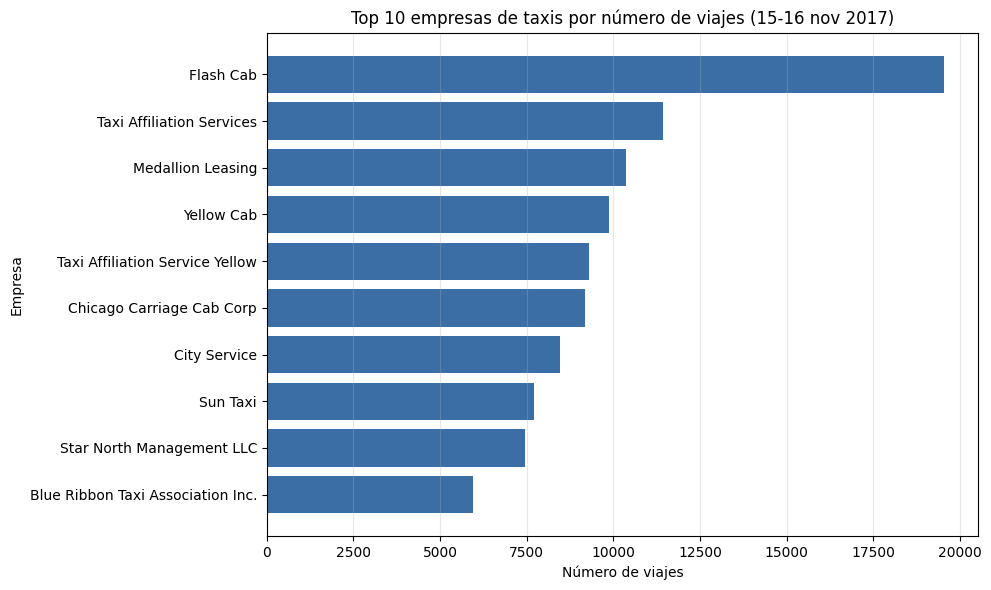

In [11]:
companies_sorted = companies.sort_values('trips_amount', ascending=False)

# Top 10 de empresas por número de viajes
top10_companies = companies_sorted.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10_companies['company_name'], top10_companies['trips_amount'], color='#3b6ea5')
ax.invert_yaxis()
ax.set_title('Top 10 empresas de taxis por número de viajes (15-16 nov 2017)')
ax.set_xlabel('Número de viajes')
ax.set_ylabel('Empresa')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
total = companies['trips_amount'].sum()
for n in (1, 3, 10):
    share = companies_sorted['trips_amount'].head(n).sum() / total * 100
    print(f'Top {n}: {share:.1f}% de los viajes')

Top 1: 14.2% de los viajes
Top 3: 30.1% de los viajes
Top 10: 72.3% de los viajes


**Conclusiones (empresas):**
- **Flash Cab** es claramente el líder, con ≈19 600 viajes en dos días, casi el doble que la segunda empresa (**Taxi Affiliation Services**, ≈11 400).
- Le siguen Medallion Leasing, Yellow Cab, Taxi Affiliation Service Yellow y Chicago Carriage Cab Corp, todas con entre ≈9 000 y ≈10 400 viajes.
- El mercado está **muy concentrado**: las 10 primeras empresas hacen alrededor del 72% de los viajes, mientras que decenas de empresas pequeñas (muchas son conductores individuales con un código en el nombre) tienen menos de 50 viajes.
- **Para Zuber:** los competidores relevantes son pocos y grandes. Conviene estudiar a Flash Cab y Taxi Affiliation Services (precios, cobertura, flota) y ver la fragmentación de la "cola larga" como oportunidad para captar conductores independientes.

### 4.2 Top 10 de barrios por número de finalizaciones (noviembre 2017)

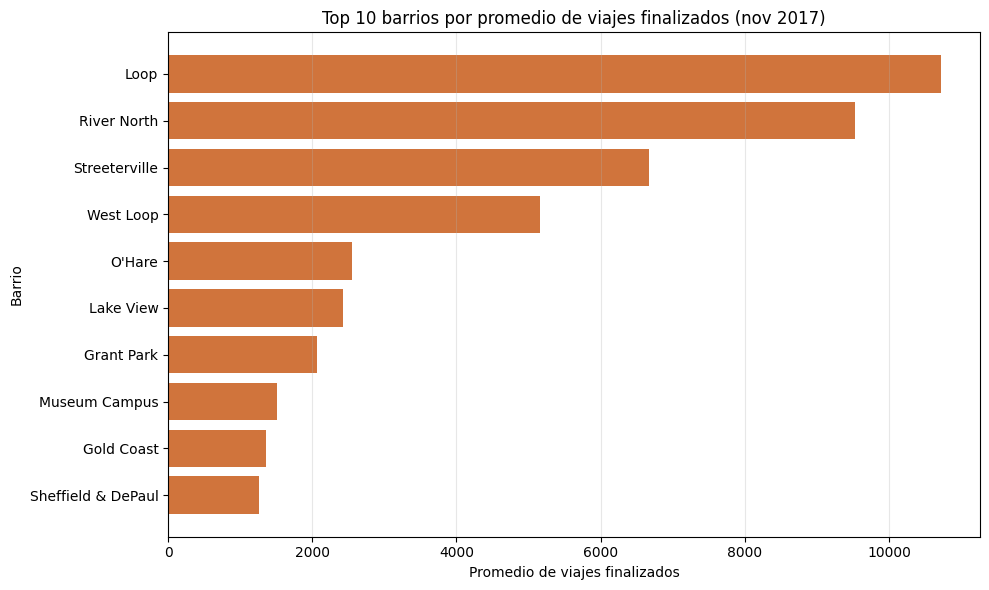

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10_neighborhoods['dropoff_location_name'], top10_neighborhoods['average_trips'], color='#d0743c')
ax.invert_yaxis()
ax.set_title('Top 10 barrios por promedio de viajes finalizados (nov 2017)')
ax.set_xlabel('Promedio de viajes finalizados')
ax.set_ylabel('Barrio')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Conclusiones (barrios):**
- **Loop** (≈10 700) y **River North** (≈9 500) son los destinos más frecuentes, seguidos de **Streeterville** (≈6 700) y **West Loop** (≈5 200). Son el centro financiero, comercial y turístico de Chicago.
- Después hay un salto grande: **O'Hare** (≈2 500), el aeropuerto internacional, es el único destino fuera del centro en el top 5. Lake View, Grant Park, Museum Campus, Gold Coast y Sheffield & DePaul completan el top 10.
- La demanda se concentra en unos pocos barrios céntricos: los 4 primeros superan con mucho al resto.
- **Para Zuber:** en el lanzamiento conviene concentrar conductores en el centro (Loop, River North, Streeterville, West Loop) y en la ruta hacia el aeropuerto O'Hare.

## 5. Prueba de hipótesis

**Hipótesis a probar:** "La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare cambia los sábados lluviosos".

- **H₀ (nula):** la duración promedio de los viajes Loop → O'Hare en sábados lluviosos (`Bad`) es **igual** a la de los sábados sin lluvia (`Good`).
- **H₁ (alternativa):** la duración promedio **es diferente** (prueba bilateral, porque la hipótesis dice "cambia", no "aumenta").

La hipótesis nula siempre se formula con el signo de igualdad; la alternativa es lo que queremos comprobar.

**Criterio:** como comparamos las **medias de dos muestras independientes** (viajes con buen y mal tiempo), uso la prueba t de Student para dos muestras, `scipy.stats.ttest_ind`. Antes, compruebo con la **prueba de Levene** si las varianzas de ambos grupos son iguales para decidir el parámetro `equal_var`.

**Nivel de significación:** α = 0.05 (5%), el valor estándar: aceptamos un 5% de probabilidad de rechazar H₀ siendo verdadera.

In [14]:
bad = trips.loc[trips['weather_conditions'] == 'Bad', 'duration_seconds']
good = trips.loc[trips['weather_conditions'] == 'Good', 'duration_seconds']

summary = trips.groupby('weather_conditions')['duration_seconds'].agg(['count', 'mean', 'median', 'std'])
summary['mean_min'] = summary['mean'] / 60
summary

,count,mean,median,std,mean_min
weather_conditions,,,,,
Bad,148,2409.229730,2463.5,751.544705,40.153829
Good,717,2049.259414,1916.0,753.877274,34.154324


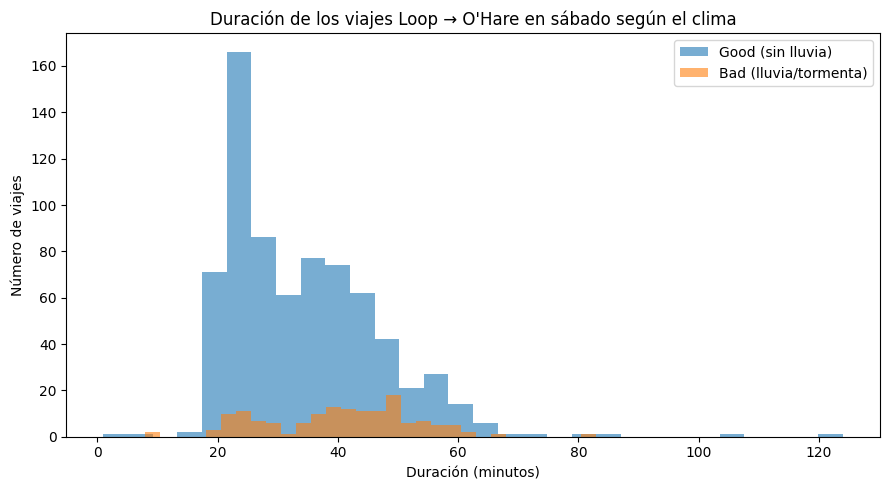

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(good / 60, bins=30, alpha=0.6, label='Good (sin lluvia)')
ax.hist(bad / 60, bins=30, alpha=0.6, label='Bad (lluvia/tormenta)')
ax.set_title("Duración de los viajes Loop → O'Hare en sábado según el clima")
ax.set_xlabel('Duración (minutos)')
ax.set_ylabel('Número de viajes')
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
alpha = 0.05

# 1) Prueba de Levene: H0 = las varianzas de ambos grupos son iguales
levene_result = st.levene(bad, good)
print('Levene p-value:', levene_result.pvalue)
equal_var = levene_result.pvalue >= alpha
print('¿Varianzas iguales?:', equal_var)

# 2) Prueba t para dos muestras independientes
results = st.ttest_ind(bad, good, equal_var=equal_var)
print('t-statistic:', results.statistic)
print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('Rechazamos la hipótesis nula: la duración promedio cambia los sábados lluviosos')
else:
    print('No podemos rechazar la hipótesis nula: no hay evidencia de que la duración cambie')

Levene p-value: 0.8195171648369002
¿Varianzas iguales?: True
t-statistic: 5.291478968158593
p-value: 1.5394237752380357e-07
Rechazamos la hipótesis nula: la duración promedio cambia los sábados lluviosos


**Resultado e interpretación** (con los datos limpios: 865 viajes):
- La prueba de Levene da un p-value ≈ 0.82 > 0.05, así que no hay evidencia de varianzas distintas y usamos `equal_var=True`.
- La prueba t da un p-value ≈ 1.54×10⁻⁷, muchísimo menor que α = 0.05 → **rechazamos la hipótesis nula**.
- En sábados con lluvia o tormenta el viaje Loop → O'Hare dura en promedio **≈40.2 minutos** (≈2 409 s) frente a **≈34.2 minutos** (≈2 049 s) con buen tiempo: unos **6 minutos más (≈360 s, ≈18%)**.
- Ojo: la muestra de días lluviosos es más pequeña (148 viajes frente a 717) y proviene de solo 4 sábados, y la hora de salida también influye en la duración. Aun así, la diferencia es grande y estadísticamente muy significativa.

## 6. Conclusión general

1. **Datos:** los tres archivos no tenían valores ausentes. Convertí `start_ts` a `datetime` (los demás tipos eran correctos) y en `trips` eliminé 197 filas duplicadas y 6 viajes con duración 0 s, quedando 865 viajes (Good = 717, Bad = 148).
2. **Competencia:** el mercado de taxis de Chicago está dominado por pocas empresas. **Flash Cab** lidera con amplia ventaja, seguida de **Taxi Affiliation Services**; las 10 primeras hacen ≈72% de los viajes.
3. **Demanda geográfica:** los destinos más populares son el centro de la ciudad (**Loop, River North, Streeterville, West Loop**) y el **aeropuerto O'Hare**.
4. **Clima:** la lluvia **sí cambia** la duración de los viajes Loop → O'Hare los sábados: son ≈6 minutos más largos en promedio (≈40.2 vs ≈34.2 min; p-value ≈ 1.54×10⁻⁷ < 0.05).

**Recomendaciones para Zuber:** concentrar oferta de conductores en el centro y en la ruta al aeropuerto; en días de lluvia, prever tiempos de viaje más largos (ajustar estimaciones de llegada, tarifas y número de conductores disponibles).